# LAB 5 - Simple and Multiple Linear Regression

**Student:** Yash Rajput  &nbsp;|&nbsp;  **Registration No:** 2427010652

Implement **Simple** and **Multiple Linear Regression** on the diabetes dataset to predict a
continuous value (**BMI**) and analyse the regression coefficients.

## 1. Import libraries and load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

df = pd.read_csv("LAB1_cleaned_data.csv")
print("Shape:", df.shape)
df.head()

Shape: (768, 9)


,Pregnant,Glucose,Diastolic_BP,Skin_Fold,Serum_Insulin,BMI,Diabetes_Pedigree,Age,Class
0,6,148.0,72.0,35.0,125.0,33.6,0.627,50,1
1,1,85.0,66.0,29.0,125.0,26.6,0.351,31,0
2,8,183.0,64.0,29.0,125.0,23.3,0.672,32,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1


## 2. Simple Linear Regression  (BMI vs Skin_Fold)

One predictor. `Skin_Fold` has the strongest correlation with `BMI` (~0.54), so it is used
as the single input feature.

In [2]:
X_s = df[["Skin_Fold"]]
y_s = df["BMI"]

Xs_train, Xs_test, ys_train, ys_test = train_test_split(
    X_s, y_s, test_size=0.25, random_state=42
)

slr = LinearRegression()
slr.fit(Xs_train, ys_train)
ys_pred = slr.predict(Xs_test)

print("Intercept (b0):", round(slr.intercept_, 4))
print("Coefficient (b1) for Skin_Fold:", round(slr.coef_[0], 4))
print("Equation: BMI = {:.4f} + {:.4f} * Skin_Fold".format(slr.intercept_, slr.coef_[0]))

Intercept (b0):

 18.8067
Coefficient (b1) for Skin_Fold: 0.47
Equation: BMI = 18.8067 + 0.4700 * Skin_Fold


In [3]:
print("Simple Linear Regression performance:")
print("R2  :", round(r2_score(ys_test, ys_pred), 4))
print("MAE :", round(mean_absolute_error(ys_test, ys_pred), 4))
print("MSE :", round(mean_squared_error(ys_test, ys_pred), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(ys_test, ys_pred)), 4))

Simple Linear Regression performance:
R2  : 0.1756
MAE : 4.5353
MSE : 38.6681
RMSE: 6.2184


### 2.1 Regression line

C:\Users\Dell\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


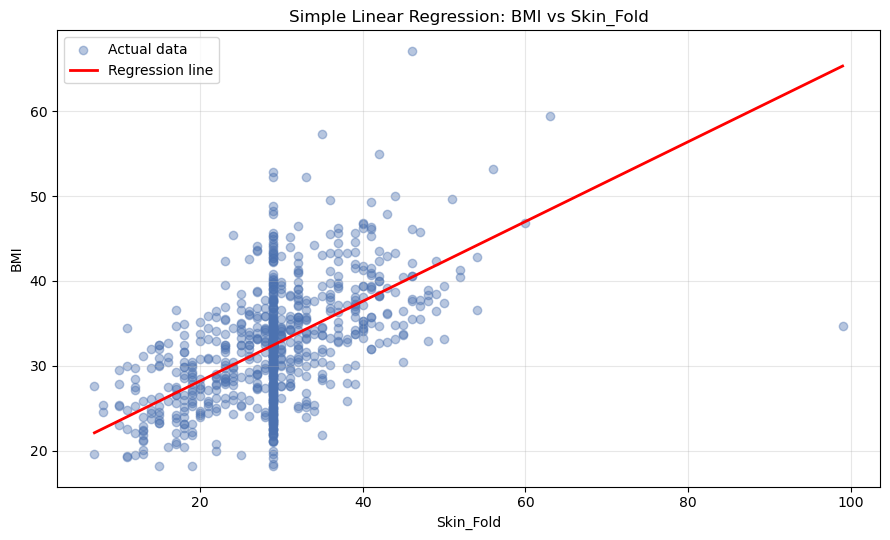

In [4]:
plt.figure(figsize=(9, 5.5))
plt.scatter(X_s, y_s, alpha=0.4, label="Actual data", color="#4C72B0")

line_x = np.linspace(X_s["Skin_Fold"].min(), X_s["Skin_Fold"].max(), 100).reshape(-1, 1)
line_y = slr.predict(line_x)
plt.plot(line_x, line_y, color="red", linewidth=2, label="Regression line")

plt.xlabel("Skin_Fold")
plt.ylabel("BMI")
plt.title("Simple Linear Regression: BMI vs Skin_Fold")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 3. Multiple Linear Regression  (BMI vs all features)

Now every other numeric feature is used to predict `BMI` (the binary label `Class` is dropped).

In [5]:
X_m = df.drop(columns=["BMI", "Class"])
y_m = df["BMI"]
print("Predictors used:", list(X_m.columns))

Xm_train, Xm_test, ym_train, ym_test = train_test_split(
    X_m, y_m, test_size=0.25, random_state=42
)

mlr = LinearRegression()
mlr.fit(Xm_train, ym_train)
ym_pred = mlr.predict(Xm_test)

print("\nIntercept (b0):", round(mlr.intercept_, 4))

Predictors used: ['Pregnant', 'Glucose', 'Diastolic_BP', 'Skin_Fold', 'Serum_Insulin', 'Diabetes_Pedigree', 'Age']

Intercept (b0): 10.5619


### 3.1 Regression coefficients

In [6]:
coef = pd.DataFrame({
    "Feature": X_m.columns,
    "Coefficient": mlr.coef_
}).sort_values("Coefficient", key=abs, ascending=False)
coef.round(4)

,Feature,Coefficient
5,Diabetes_Pedigree,1.4134
3,Skin_Fold,0.4292
2,Diastolic_BP,0.0958
6,Age,-0.0754
1,Glucose,0.0319
0,Pregnant,-0.0055
4,Serum_Insulin,0.0032


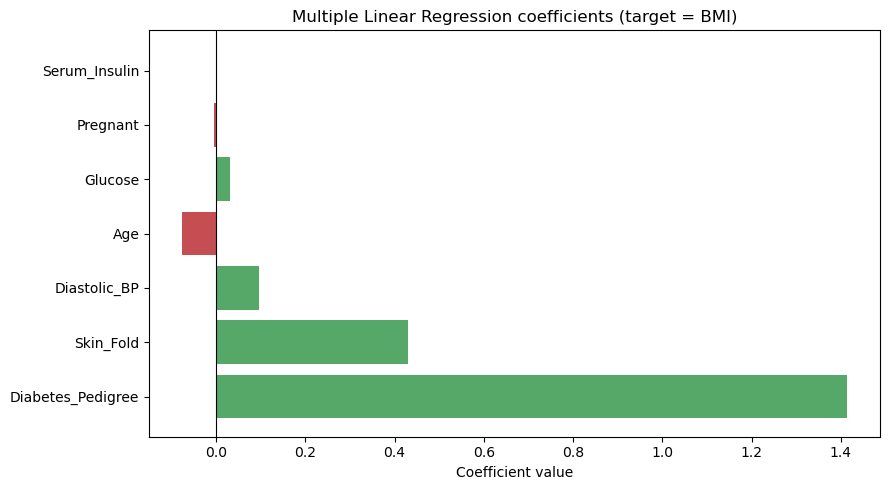

In [7]:
plt.figure(figsize=(9, 5))
colors = ["#55A868" if c >= 0 else "#C44E52" for c in coef["Coefficient"]]
plt.barh(coef["Feature"], coef["Coefficient"], color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Coefficient value")
plt.title("Multiple Linear Regression coefficients (target = BMI)")
plt.tight_layout()
plt.show()

In [8]:
print("Multiple Linear Regression performance:")
print("R2  :", round(r2_score(ym_test, ym_pred), 4))
print("MAE :", round(mean_absolute_error(ym_test, ym_pred), 4))
print("MSE :", round(mean_squared_error(ym_test, ym_pred), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(ym_test, ym_pred)), 4))

Multiple Linear Regression performance:
R2  : 0.2505
MAE : 4.4594
MSE : 35.1577
RMSE: 5.9294


### 3.2 Actual vs Predicted BMI

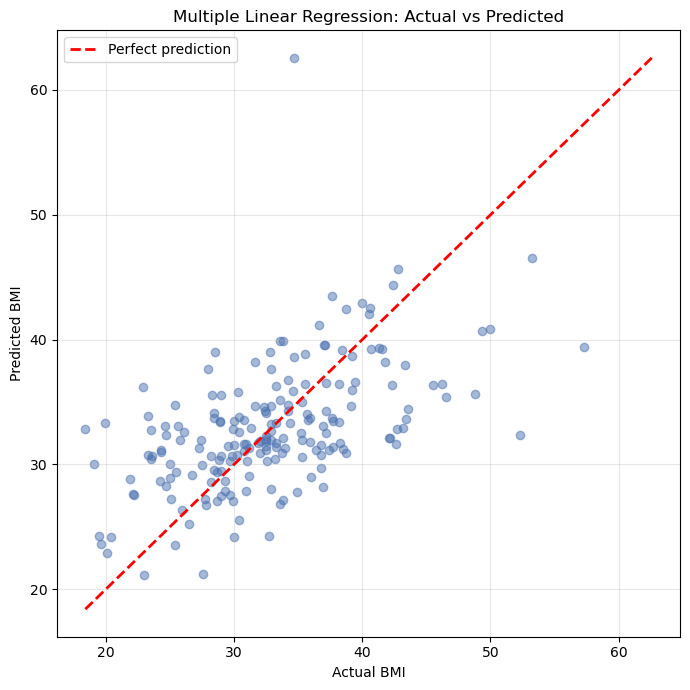

In [9]:
plt.figure(figsize=(7, 7))
plt.scatter(ym_test, ym_pred, alpha=0.5, color="#4C72B0")
lims = [min(ym_test.min(), ym_pred.min()), max(ym_test.max(), ym_pred.max())]
plt.plot(lims, lims, "r--", linewidth=2, label="Perfect prediction")
plt.xlabel("Actual BMI")
plt.ylabel("Predicted BMI")
plt.title("Multiple Linear Regression: Actual vs Predicted")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Comparison of the two models

      Simple LR (Skin_Fold)  Multiple LR (all features)
R2                   0.1756                      0.2505
MAE                  4.5353                      4.4594
RMSE                 6.2184                      5.9294


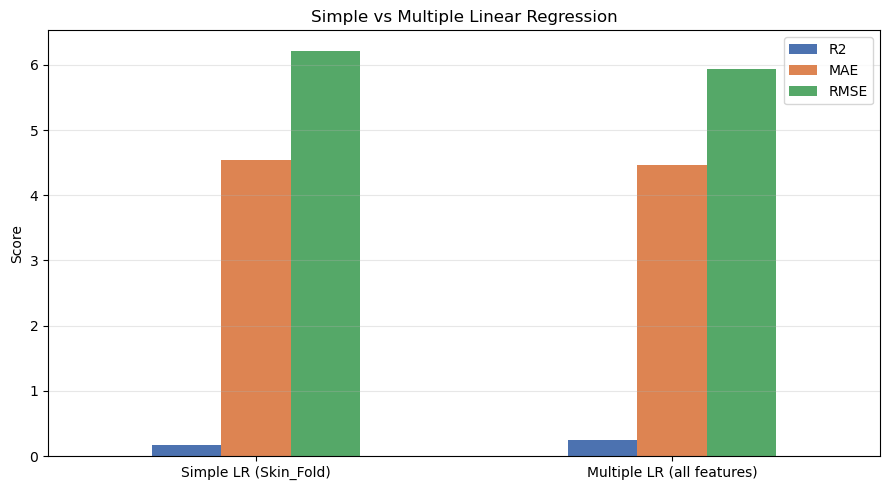

In [10]:
compare = pd.DataFrame({
    "Simple LR (Skin_Fold)": [
        r2_score(ys_test, ys_pred),
        mean_absolute_error(ys_test, ys_pred),
        np.sqrt(mean_squared_error(ys_test, ys_pred)),
    ],
    "Multiple LR (all features)": [
        r2_score(ym_test, ym_pred),
        mean_absolute_error(ym_test, ym_pred),
        np.sqrt(mean_squared_error(ym_test, ym_pred)),
    ],
}, index=["R2", "MAE", "RMSE"])
print(compare.round(4))

compare.T.plot(kind="bar", figsize=(9, 5), color=["#4C72B0", "#DD8452", "#55A868"])
plt.title("Simple vs Multiple Linear Regression")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()